# Desempleo en Bogotá: tasa anual y proyección para enero–marzo de 2027

En este notebook reviso cómo ha cambiado el desempleo en Bogotá entre 2022 y 2026 y hago una proyección sencilla para el primer trimestre de 2027.

Trabajo con dos archivos descargados de Datos Abiertos Bogotá:
- `bogota_mercado_laboral.xlsx` (hoja `Mercado laboral Bogotá`): 49 trimestres móviles, desde enero–marzo de 2022 hasta enero–marzo de 2026. El último dato termina el 31 de marzo de 2026.
- `bogota_metadatos.xlsx` (hoja `Metadata conjunto`): el diccionario que explica cada columna.

Algo a tener en cuenta: los datos vienen en trimestres móviles (ene–mar, feb–abr, mar–may...), así que cada periodo comparte meses con el siguiente. Por eso no sumo personas entre periodos y, para la tasa anual, uso solo cuatro trimestres que no se cruzan. Para la proyección sí uso la serie completa.

## Preparación de los datos
Al revisar el diccionario noté que los nombres de las tres primeras columnas no coinciden con lo que contienen: **Periodo** trae etiquetas como "ene mar", **Trimestre** trae el mes en que empieza el periodo (de 1 a 12) y **Trimestre móvil cronológico** trae el año, o dos años cuando el periodo cruza diciembre. Les cambio el nombre solo dentro del notebook, sin tocar el Excel. Cuando un periodo abarca dos años, tomo el primero y compruebo que el año final también cuadre.

La tasa de desocupación ya viene en porcentaje (8,8 significa 8,8 %). Para asegurarme de que está bien, la recalculo como desocupados / fuerza de trabajo × 100 y comparo los dos valores.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore", message="Data Validation extension is not supported and will be removed")
archivo = Path("bogota_mercado_laboral.xlsx")
original = pd.read_excel(archivo, sheet_name="Mercado laboral Bogotá")
metadatos = pd.read_excel("bogota_metadatos.xlsx", sheet_name="Metadata conjunto")
display(metadatos.iloc[:3, :3])
display(original.iloc[[0, 10, 11], :3])
datos = original.dropna(how="all").copy()
datos.columns = [" ".join(c.split()) for c in datos.columns]
datos = datos.rename(columns={"Periodo": "trimestre", "Trimestre": "mes_inicial",
                              "Trimestre móvil cronológico": "periodo_anual"})


,Nombre del Campo,Descripción del campo,Tipo de dato
0,Periodo,Corresponde al año de referencia de la informa...,Númerico
1,Trimestre,Corresponde al trimestre móvil de referencia d...,Texto
2,Trimestre móvil cronológico,Corresponde al número asignado a cada trimestr...,Númerico


,Periodo,Trimestre,Trimestre móvil cronológico
0,ene mar,1,2022
10,nov ene,11,2022 - 2023
11,dic feb,12,2022 - 2023


In [2]:
etiquetas = ["ene mar", "feb abr", "mar may", "abr jun", "may jul", "jun ago",
             "jul sep", "ago oct", "sep nov", "oct dic", "nov ene", "dic feb"]
mes = pd.to_numeric(datos["mes_inicial"], errors="raise")
assert mes.between(1, 12).all() and mes.mod(1).eq(0).all()
assert datos["trimestre"].eq(mes.map(dict(enumerate(etiquetas, 1)))).all()
anios = datos["periodo_anual"].astype(str).str.findall(r"[0-9]{4}")
assert anios.str.len().between(1, 2).all()
datos["inicio"] = pd.to_datetime(dict(year=anios.str[0].astype(int),
                                     month=mes.astype(int), day=1))
datos["fin"] = datos["inicio"] + pd.offsets.MonthEnd(3)
assert datos["fin"].dt.year.eq(anios.str[-1].astype(int)).all()
datos = datos.sort_values("fin").reset_index(drop=True)
assert datos["fin"].is_unique
assert datos["fin"].dt.to_period("M").tolist() == list(
    pd.period_range(datos["fin"].min(), datos["fin"].max(), freq="M"))
campos = ["Desocupados", "Fuerza de trabajo", "Tasa de desocupacion"]
datos[campos] = datos[campos].apply(pd.to_numeric, errors="raise")
assert datos[campos].notna().all().all()
assert datos["Fuerza de trabajo"].gt(0).all()
assert datos["Tasa de desocupacion"].between(0, 100).all()
tasa_calculada = datos["Desocupados"] / datos["Fuerza de trabajo"] * 100
assert np.allclose(datos["Tasa de desocupacion"], tasa_calculada, atol=0.0001)
print("Archivo:", archivo.name)
print("Inicio del primer trimestre:", datos["inicio"].min().date())
print("Fin del último trimestre:", datos["fin"].max().date())
print("Número de trimestres móviles:", len(datos))


Archivo: bogota_mercado_laboral.xlsx
Inicio del primer trimestre: 2022-01-01
Fin del último trimestre: 2026-03-31
Número de trimestres móviles: 49


## 1. Desempleo por año
Para tener una cifra por año tomo los trimestres enero–marzo, abril–junio, julio–septiembre y octubre–diciembre, que juntos cubren el año sin repetir meses. Solo incluyo los años que tienen los cuatro.

La tasa anual la calculo como el promedio de desocupados dividido entre el promedio de la fuerza de trabajo, y no como el promedio de las cuatro tasas. Es una estimación hecha a partir del Excel, no la cifra anual oficial. 2026 queda por fuera porque solo tiene el primer trimestre.

In [3]:
trimestres = datos.loc[datos["mes_inicial"].isin([1, 4, 7, 10])].copy()
trimestres["año"] = trimestres["inicio"].dt.year
assert not trimestres.duplicated(["año", "mes_inicial"]).any()
completos = trimestres.groupby("año")["mes_inicial"].agg(
    lambda valores: set(valores) == {1, 4, 7, 10})
anios_completos = completos.index[completos]
anual = trimestres.loc[trimestres["año"].isin(anios_completos)].groupby("año")[
    ["Desocupados", "Fuerza de trabajo"]].mean()
anual["Tasa anual estimada (%)"] = anual["Desocupados"] / anual["Fuerza de trabajo"] * 100
assert len(anual) > 0
print("Años excluidos por estar incompletos:", completos.index[~completos].tolist())
display(anual.round(2))


Años excluidos por estar incompletos: [2026]


,Desocupados,Fuerza de trabajo,Tasa anual estimada (%)
año,,,
2022,491404.75,4303901.33,11.42
2023,469927.92,4519753.65,10.40
2024,453629.49,4671596.05,9.71
2025,387149.38,4697766.25,8.24


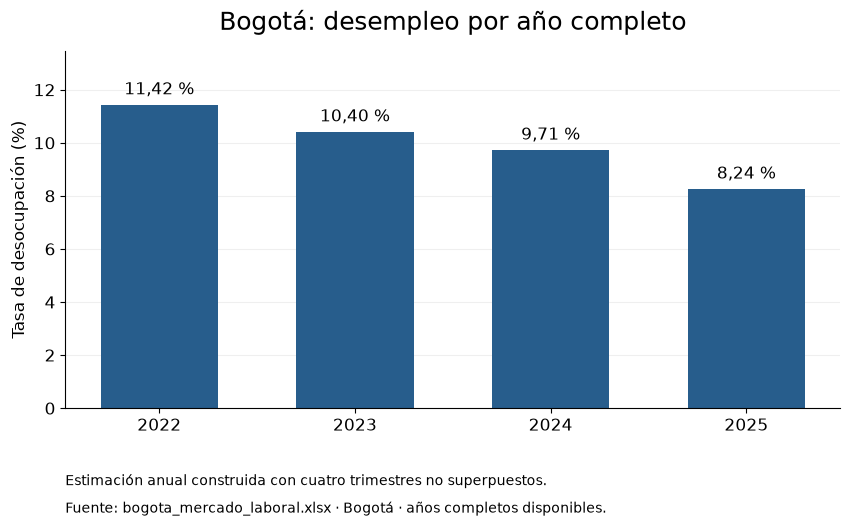

In [4]:
plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False})
azul, naranja = "#275D8C", "#C26323"
def porcentaje(valor):
    return f"{valor:.2f} %".replace(".", ",")

fig, eje = plt.subplots(figsize=(10, 5.5))
valores = anual["Tasa anual estimada (%)"]
barras = eje.bar(anual.index.astype(str), valores, color=azul, width=0.6)
eje.bar_label(barras, labels=[porcentaje(v) for v in valores], padding=5)
eje.set_title("Bogotá: desempleo por año completo", fontsize=18, pad=15)
eje.set_ylabel("Tasa de desocupación (%)")
eje.set_ylim(0, valores.max() * 1.18)
eje.grid(axis="y", alpha=0.2)
eje.set_axisbelow(True)
fig.subplots_adjust(bottom=0.23)
fig.text(0.125, 0.09, "Estimación anual construida con cuatro trimestres no superpuestos.", fontsize=10)
fig.text(0.125, 0.04, "Fuente: bogota_mercado_laboral.xlsx · Bogotá · años completos disponibles.", fontsize=10)
fig.savefig("desempleo_anual.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Proyección para enero–marzo de 2027
Para la proyección uso una regresión Ridge, que es una regresión lineal con un ajuste que evita que el modelo le dé demasiado peso a una sola variable. El modelo intenta predecir la tasa de cada periodo a partir de:
- las tasas de 1, 2, 3 y 12 periodos atrás, y
- el mes en que termina el periodo (convertido en seno y coseno), para capturar patrones que se repiten cada año.

Dejo el parámetro alpha en 1 y no lo ajusto mirando los resultados de la prueba.

Antes de proyectar quise saber qué tan bien funciona. Separé los últimos 12 periodos (abril de 2025 a marzo de 2026) como prueba, entrené el modelo con los datos hasta marzo de 2025 y pronostiqué esos 12 periodos paso a paso, sin dejar que viera los valores reales. Escogí 12 porque es la misma distancia que hay entre marzo de 2026 y marzo de 2027. Para comparar uso una referencia muy simple: repetir el último valor conocido. El error lo mido con el MAE (error absoluto medio), en puntos porcentuales. Son pocos datos de prueba, así que este resultado hay que tomarlo con cautela.

In [5]:
serie = datos.set_index("fin")["Tasa de desocupacion"]
rezagos = [1, 2, 3, 12]
def variables(historia, fecha):
    return [historia[-r] for r in rezagos] + [
        np.sin(2 * np.pi * fecha.month / 12),
        np.cos(2 * np.pi * fecha.month / 12)]

def entrenar(historia):
    valores = historia.to_numpy()
    X = [variables(valores[:i], historia.index[i]) for i in range(12, len(valores))]
    modelo = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    modelo.fit(X, valores[12:])
    return modelo

def proyectar(modelo, historia, fechas):
    valores = list(historia.to_numpy())
    predicciones = []
    for fecha in fechas:
        valor = float(modelo.predict([variables(valores, fecha)])[0])
        predicciones.append(valor)
        valores.append(valor)
    return np.array(predicciones)


In [6]:
entrenamiento, prueba = serie.iloc[:-12], serie.iloc[-12:]
assert entrenamiento.index.max() < prueba.index.min()
modelo_prueba = entrenar(entrenamiento)
pred_prueba = proyectar(modelo_prueba, entrenamiento, prueba.index)
mae_ridge = mean_absolute_error(prueba, pred_prueba)
mae_base = mean_absolute_error(prueba, np.repeat(entrenamiento.iloc[-1], len(prueba)))
print("Entrenamiento hasta:", entrenamiento.index[-1].date())
print("Prueba:", prueba.index[0].date(), "a", prueba.index[-1].date())
display(pd.DataFrame({"Método": ["Ridge recursiva", "Repetir último valor"],
                      "MAE de prueba (pp)": [mae_ridge, mae_base]}).round(3))


Entrenamiento hasta: 2025-03-31
Prueba: 2025-04-30 a 2026-03-31


,Método,MAE de prueba (pp)
0,Ridge recursiva,1.406
1,Repetir último valor,2.047


In [7]:
# Reajuste con toda la serie, nunca con los promedios anuales.
modelo_final = entrenar(serie)
futuros = pd.period_range(serie.index[-1].to_period("M") + 1, "2027-03", freq="M")
fechas = futuros.to_timestamp("M")
pronostico = pd.DataFrame({"fin": fechas,
                          "tasa estimada (%)": proyectar(modelo_final, serie, fechas)})
pronostico["inicio"] = (futuros - 2).to_timestamp()
assert len(pronostico) == 12
assert pronostico["tasa estimada (%)"].between(0, 100).all()
display(pronostico[["inicio", "fin", "tasa estimada (%)"]].round(2))
estimacion_2027 = pronostico["tasa estimada (%)"].iloc[-1]
primeros = datos.loc[datos["mes_inicial"].eq(1)].copy()
primeros["año"] = primeros["inicio"].dt.year
assert primeros["año"].is_unique
tasa_2026 = primeros.loc[primeros["año"].eq(2026), "Tasa de desocupacion"].item()
cambio = estimacion_2027 - tasa_2026


C:\Users\USER\AppData\Local\Temp\ipykernel_38300\214069232.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pronostico[["inicio", "fin", "tasa estimada (%)"]].round(2))


,inicio,fin,tasa estimada (%)
0,2026-02-01,2026-04-30,8.34
1,2026-03-01,2026-05-31,8.03
2,2026-04-01,2026-06-30,7.74
3,2026-05-01,2026-07-31,7.64
4,2026-06-01,2026-08-31,7.47
5,2026-07-01,2026-09-30,7.37
6,2026-08-01,2026-10-31,7.21
7,2026-09-01,2026-11-30,6.91
8,2026-10-01,2026-12-31,6.59
9,2026-11-01,2027-01-31,6.82


### Enero–marzo: datos reales y proyección
Las barras azules son las tasas reales de enero–marzo de cada año según el Excel. La barra naranja es lo que proyecta el modelo para enero–marzo de 2027. Para llegar ahí el modelo avanza un periodo a la vez: cuando necesita un dato que todavía no existe, usa su propia predicción anterior.

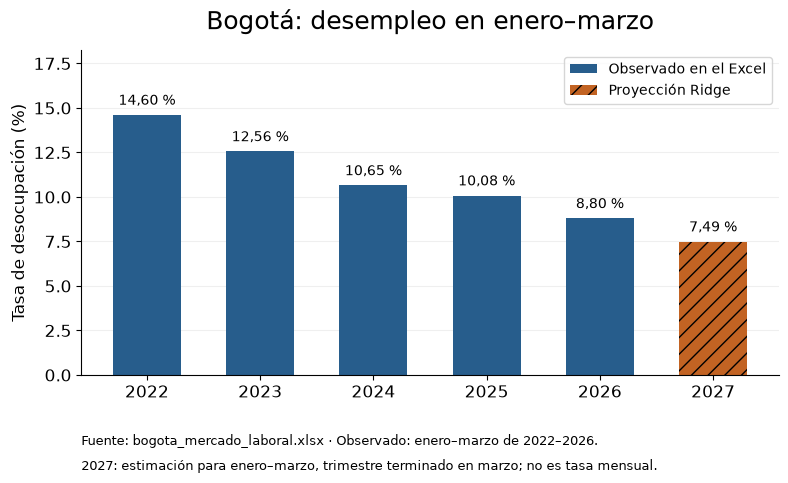

In [8]:
fig, eje = plt.subplots(figsize=(9, 5))
anios = primeros["año"].astype(str).tolist() + ["2027"]
tasas = primeros["Tasa de desocupacion"].tolist() + [estimacion_2027]
barras = eje.bar(anios, tasas, color=[azul] * len(primeros) + [naranja], width=0.6)
barras[-1].set_hatch("//")
eje.bar_label(barras, labels=[porcentaje(v) for v in tasas], padding=5, fontsize=10)
barras[0].set_label("Observado en el Excel")
barras[-1].set_label("Proyección Ridge")
eje.set_title("Bogotá: desempleo en enero–marzo", fontsize=18, pad=15)
eje.set_ylabel("Tasa de desocupación (%)")
eje.set_ylim(0, max(tasas) * 1.25)
eje.legend(fontsize=10, loc="upper right")
eje.grid(axis="y", alpha=0.2)
eje.set_axisbelow(True)
fig.subplots_adjust(bottom=0.23)
fig.text(0.125, 0.09, "Fuente: bogota_mercado_laboral.xlsx · Observado: enero–marzo de 2022–2026.", fontsize=9)
fig.text(0.125, 0.04, "2027: estimación para enero–marzo, trimestre terminado en marzo; no es tasa mensual.", fontsize=9)
fig.savefig("proyeccion_ene_mar_2027.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
direccion = "un aumento" if cambio > 0 else "una disminución" if cambio < 0 else "un cambio"
comparacion = ("En esta prueba funcionó mejor que la referencia." if mae_ridge < mae_base else
              "En esta prueba no funcionó mejor que la referencia, así que no tengo evidencia para preferir Ridge.")
display(Markdown(
    f"Usé **Ridge** con las tasas de periodos anteriores y el mes del año, y al final lo volví a entrenar "
    f"con los 49 trimestres móviles. En la prueba se equivocó en promedio "
    f"**{mae_ridge:.3f} puntos porcentuales**, frente a {mae_base:.3f} si simplemente repito "
    f"el último valor. {comparacion}" + chr(10) + chr(10) +
    f"Según el modelo, la tasa de enero–marzo pasaría de **{porcentaje(tasa_2026)} en 2026** "
    f"a **{porcentaje(estimacion_2027)} en 2027**, es decir, {direccion} de "
    f"**{abs(cambio):.2f} puntos porcentuales**." + chr(10) + chr(10) +
    "**Esto es una estimación, no una certeza.** La prueba tiene solo 12 periodos, que además se parecen "
    "mucho entre sí porque comparten meses, y la serie es corta. Como cada paso usa la predicción anterior, "
    "los errores se pueden ir acumulando. No calculé un rango de incertidumbre (el MAE no lo es) y este "
    "análisis no explica las causas de los cambios en el desempleo."))

Usé **Ridge** con las tasas de periodos anteriores y el mes del año, y al final lo volví a entrenar con los 49 trimestres móviles. En la prueba se equivocó en promedio **1.406 puntos porcentuales**, frente a 2.047 si simplemente repito el último valor. En esta prueba funcionó mejor que la referencia.

Según el modelo, la tasa de enero–marzo pasaría de **8,80 % en 2026** a **7,49 % en 2027**, es decir, una disminución de **1.31 puntos porcentuales**.

**Esto es una estimación, no una certeza.** La prueba tiene solo 12 periodos, que además se parecen mucho entre sí porque comparten meses, y la serie es corta. Como cada paso usa la predicción anterior, los errores se pueden ir acumulando. No calculé un rango de incertidumbre (el MAE no lo es) y este análisis no explica las causas de los cambios en el desempleo.